In [1]:
import veloxchem as vlx
import math
import numpy as np
import matplotlib.pyplot as plt
!pwd

/home/marwad/Desktop/Ligands/TCB-3/ff-reparameterization/ff1/scans


In [2]:
# Read lowest conformer

tcb_3 = vlx.Molecule.read_xyz_file("TCC-opt.xyz")
tcb_3.show(atom_indices=True)

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

In [3]:
tcb_3.set_charge(0)
ff_gen = vlx.MMForceFieldGenerator()
ff_gen.create_topology(tcb_3)
ff_gen.write_gromacs_files("TCB_3_initial", "LIG") 

* Info * Using 6-31G* basis set for RESP charges...                                                                       
* Info * Sum of partial charges is not a whole number.                                                                    
* Info * Compensating by removing -2.000e-06 from the largest charge.                                                     
                                                                                                                          
* Info * Using GAFF (v2.11) parameters.                                                                                   
         Reference: J. Wang, R. M. Wolf, J. W. Caldwell, P. A. Kollman, D. A. Case, J. Comput. Chem. 2004,
         25, 1157-1174.
                                                                                                                          
* Info * Updated bond angle 6-7-8 (ca-cc-cd) to 128.632 deg                                                               
* Info *

In [4]:
rot_bonds = ff_gen.rotatable_bonds
print(rot_bonds)

[[2, 3], [1, 2], [26, 27], [6, 7], [10, 11], [12, 15], [27, 28]]


In [5]:
dihedral_1 = (16, 15, 12, 13)
print("Optimized ", "Dihedral angles: ",
f"{tcb_3.get_dihedral_in_degrees(dihedral_1):.2f}")

Optimized  Dihedral angles:  -179.99


In [6]:
dihedral_2 = (12, 11, 10, 24)
print("Optimized ", "Dihedral angles: ",
f"{tcb_3.get_dihedral_in_degrees(dihedral_2):.2f}")

Optimized  Dihedral angles:  -0.03


In [7]:
dihedral_3 = (24, 7, 6, 25)
print("Optimized ", "Dihedral angles: ",
f"{tcb_3.get_dihedral_in_degrees(dihedral_3):.2f}")

Optimized  Dihedral angles:  -0.66


# [12, 15]

                                          VeloxChem Dihedral Reparameterization                                           
                                                                                                                          
* Info * Rotatable bond selected: 12-15                                                                                   
* Info * Dihedrals involved:[[11, 12, 15, 16], [11, 12, 15, 23], [13, 12, 15, 16], [13, 12, 15, 23]]                      
                                                                                                                          
* Info * Reading QM scan from file...                                                                                     
* Info *   16-15-12-13/16-15-12-13.xyz                                                                                    
                                                                                                                          
* Info * Perform

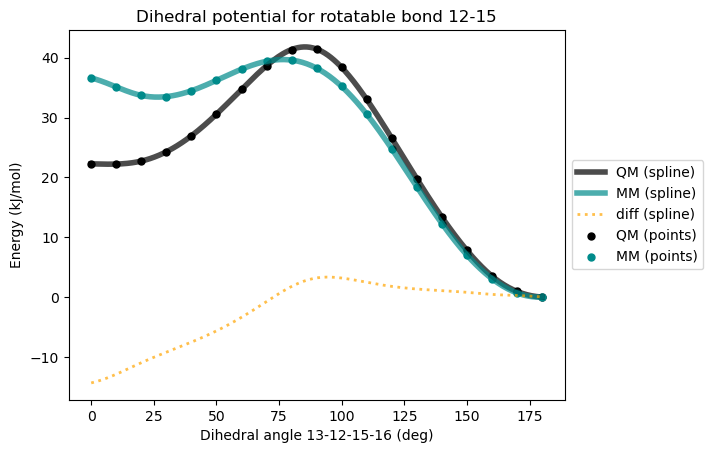

* Info * Fitting the dihedral parameters...                                                                               
* Info * Optimizing dihedral via least squares fitting...                                                                 
* Info * New fitted barriers: [5.30721158 5.30721158 5.30721158 5.30721158]                                               
                                                                                                                          
* Info * Validating the fitted force field...                                                                             
                                                                                                                          
* Info *       Dihedral      MM energy(rel)      QM energy(rel)       diff                                                
* Info *   ---------------------------------------------------------------                                                
* Info *        

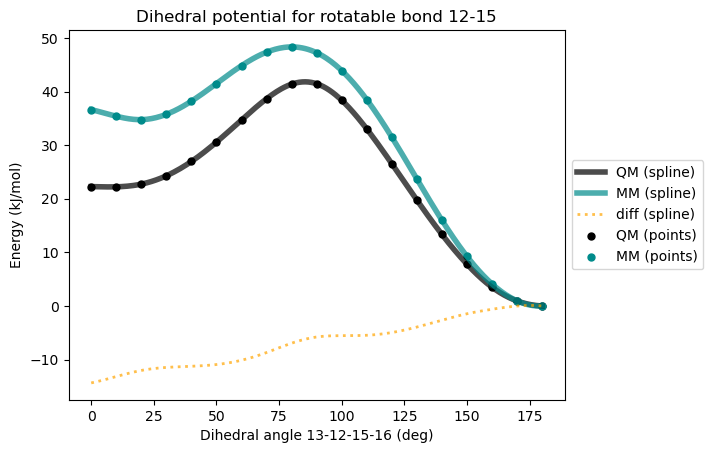

* Info * Dihedral MM parameters have been reparameterized and updated in the topology.                                    


{'dihedral_angles': array([  0.,  10.,  20.,  30.,  40.,  50.,  60.,  70.,  80.,  90., 100.,
        110., 120., 130., 140., 150., 160., 170., 180.]),
 'qm_scan_kJpermol': array([22.26528714, 22.2272174 , 22.73102452, 24.28416509, 26.9512789 ,
        30.5655417 , 34.69928587, 38.65793546, 41.37931834, 41.45561536,
        38.37566799, 33.02734144, 26.53965307, 19.76447248, 13.34937917,
         7.79321807,  3.49769062,  0.93761843,  0.        ]),
 'mm_scan_kJpermol': array([36.62236341, 35.39639763, 34.75844694, 35.751287  , 38.20082   ,
        41.49554345, 44.82637927, 47.34844052, 48.32439221, 47.24420733,
        43.91373838, 38.49643446, 31.49977503, 23.69885102, 15.99699862,
         9.25005741,  4.11027288,  0.94830092,  0.        ]),
 'maximum_difference': np.float64(14.357076264653767),
 'standard_deviation': np.float64(4.5346403979569185)}

In [8]:
ff_gen.reparameterize_dihedrals(rotatable_bond=(12,15), 
    scan_file="16-15-12-13/16-15-12-13.xyz",
    visualize=True, 
    show_diff=True)

In [9]:
ff_gen.add_dihedral((16, 15, 12, 13), 
    barrier = 0.0, 
    phase = 180, 
    periodicity = 1)

* Info * Added dihedral 13-12-15-16                                                                                       


                                          VeloxChem Dihedral Reparameterization                                           
                                                                                                                          
* Info * Rotatable bond selected: 12-15                                                                                   
* Info * Dihedrals involved:[[11, 12, 15, 16], [11, 12, 15, 23], [13, 12, 15, 16], [13, 12, 15, 23]]                      
                                                                                                                          
* Info * Reading QM scan from file...                                                                                     
* Info *   16-15-12-13/16-15-12-13.xyz                                                                                    
                                                                                                                          
* Info * Perform

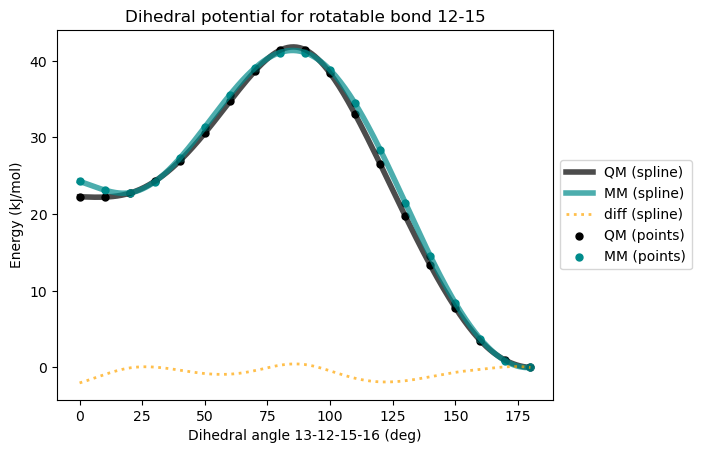

* Info * Dihedral MM parameters have been reparameterized and updated in the topology.                                    


In [10]:
results_12_15 =ff_gen.reparameterize_dihedrals(rotatable_bond=(12,15), 
    scan_file = "16-15-12-13/16-15-12-13.xyz", 
    visualize=True, 
    initial_validation=False, 
    show_diff=True)

# [11, 10]

                                          VeloxChem Dihedral Reparameterization                                           
                                                                                                                          
* Info * Rotatable bond selected: 11-10                                                                                   
* Info * Dihedrals involved:[[9, 10, 11, 12], [9, 10, 11, 36], [12, 11, 10, 24], [24, 10, 11, 36]]                        
                                                                                                                          
* Info * Reading QM scan from file...                                                                                     
* Info *   12-11-10-24/12-11-10-24.xyz                                                                                    
                                                                                                                          
* Info * Perform

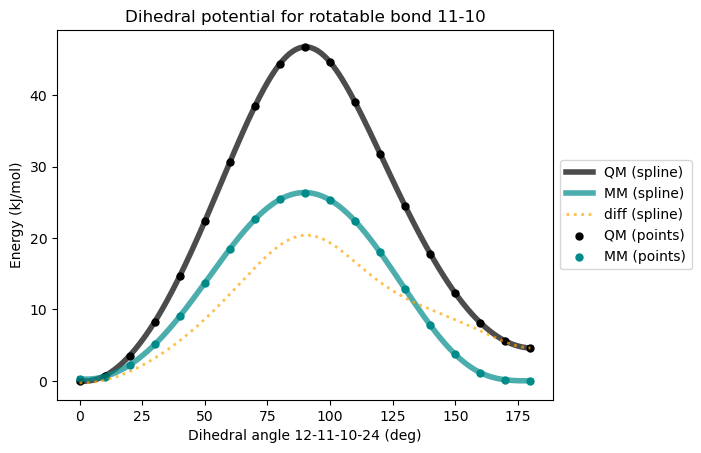

* Info * Fitting the dihedral parameters...                                                                               
* Info * Optimizing dihedral via least squares fitting...                                                                 
* Info * New fitted barriers: [6.55816604 6.55816604 6.55816604 6.55816604]                                               
                                                                                                                          
* Info * Validating the fitted force field...                                                                             
                                                                                                                          
* Info *       Dihedral      MM energy(rel)      QM energy(rel)       diff                                                
* Info *   ---------------------------------------------------------------                                                
* Info *        

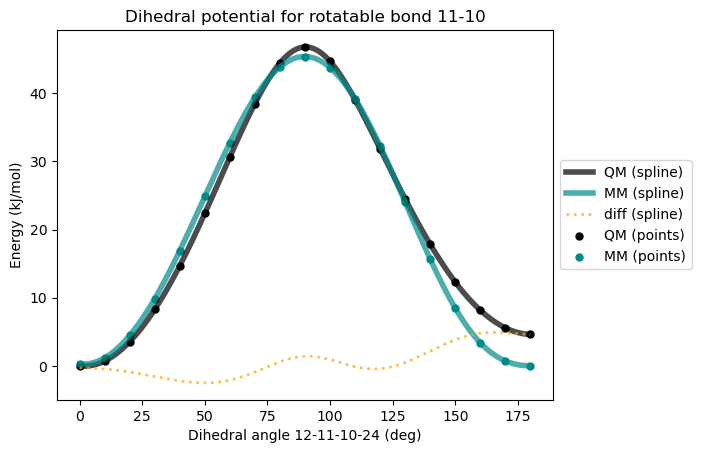

* Info * Dihedral MM parameters have been reparameterized and updated in the topology.                                    


{'dihedral_angles': array([  0.,  10.,  20.,  30.,  40.,  50.,  60.,  70.,  80.,  90., 100.,
        110., 120., 130., 140., 150., 160., 170., 180.]),
 'qm_scan_kJpermol': array([ 0.        ,  0.69772653,  3.54158897,  8.27294936, 14.68743881,
        22.3562082 , 30.64719474, 38.48323471, 44.43752658, 46.7857472 ,
        44.6628207 , 39.02235481, 31.8122077 , 24.46611222, 17.81446139,
        12.27190038,  8.1441161 ,  5.56784458,  4.60087306]),
 'mm_scan_kJpermol': array([ 0.28708065,  1.1728858 ,  4.45260416,  9.84405803, 16.89679129,
        24.86253788, 32.73747886, 39.40006006, 43.84193979, 45.37698936,
        43.74862211, 39.15834004, 32.23553477, 23.98677747, 15.64359971,
         8.45026644,  3.36377951,  0.71567798,  0.        ]),
 'maximum_difference': np.float64(4.852166598782072),
 'standard_deviation': np.float64(2.3256036751731366)}

In [11]:
ff_gen.reparameterize_dihedrals(rotatable_bond=(11,10), 
    scan_file="12-11-10-24/12-11-10-24.xyz",
    visualize=True, 
    show_diff=True)

In [12]:
ff_gen.add_dihedral((12,11,10,24), 
    barrier = 0.0, 
    phase = 180, 
    periodicity = 1)

* Info * Added dihedral 12-11-10-24                                                                                       


                                          VeloxChem Dihedral Reparameterization                                           
                                                                                                                          
* Info * Rotatable bond selected: 11-10                                                                                   
* Info * Dihedrals involved:[[9, 10, 11, 12], [9, 10, 11, 36], [12, 11, 10, 24], [24, 10, 11, 36]]                        
                                                                                                                          
* Info * Reading QM scan from file...                                                                                     
* Info *   12-11-10-24/12-11-10-24.xyz                                                                                    
                                                                                                                          
* Info * Perform

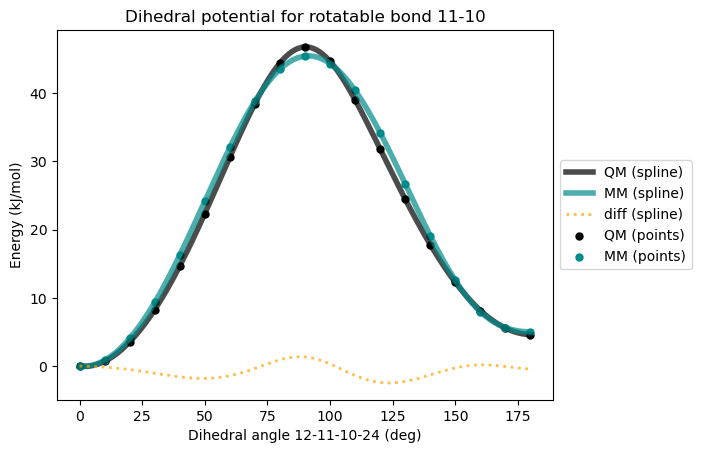

* Info * Dihedral MM parameters have been reparameterized and updated in the topology.                                    


In [13]:
results_11_10 = ff_gen.reparameterize_dihedrals(rotatable_bond=(11,10), 
    scan_file = '12-11-10-24/12-11-10-24.xyz',
    visualize=True, 
    initial_validation=False, 
    show_diff=True)

# [6, 7]

                                          VeloxChem Dihedral Reparameterization                                           
                                                                                                                          
* Info * Rotatable bond selected: 6-7                                                                                     
* Info * Dihedrals involved:[[5, 6, 7, 8], [5, 6, 7, 24], [8, 7, 6, 25], [24, 7, 6, 25]]                                  
                                                                                                                          
* Info * Reading QM scan from file...                                                                                     
* Info *   24-7-6-25/24-7-6-25.xyz                                                                                        
                                                                                                                          
* Info * Perform

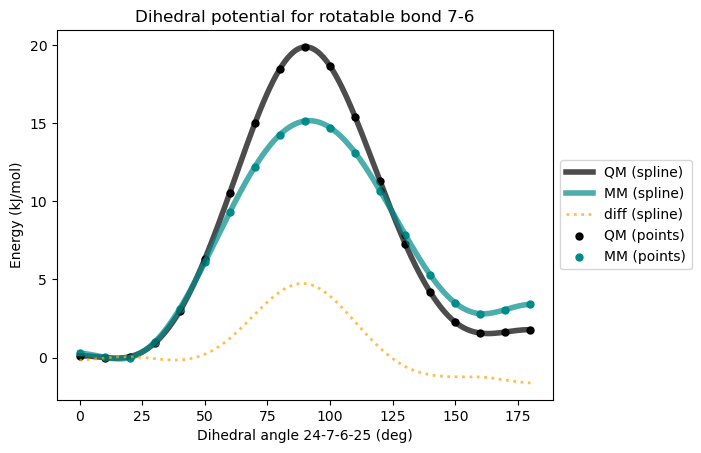

* Info * Fitting the dihedral parameters...                                                                               
* Info * Optimizing dihedral via least squares fitting...                                                                 
* Info * New fitted barriers: [3.49948038 3.49948038 3.49948038 3.49948038]                                               
                                                                                                                          
* Info * Validating the fitted force field...                                                                             
                                                                                                                          
* Info *       Dihedral      MM energy(rel)      QM energy(rel)       diff                                                
* Info *   ---------------------------------------------------------------                                                
* Info *        

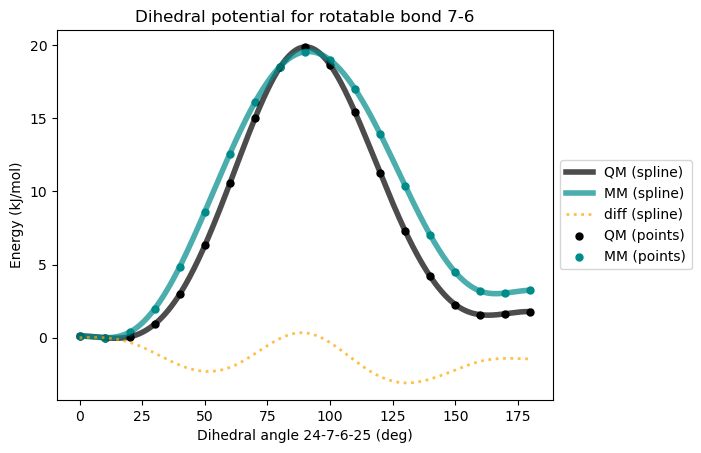

* Info * Dihedral MM parameters have been reparameterized and updated in the topology.                                    


{'dihedral_angles': array([  0.,  10.,  20.,  30.,  40.,  50.,  60.,  70.,  80.,  90., 100.,
        110., 120., 130., 140., 150., 160., 170., 180.]),
 'qm_scan_kJpermol': array([ 0.11019222,  0.        ,  0.05655326,  0.92869173,  2.9776054 ,
         6.30579376, 10.5518568 , 14.99026394, 18.48002555, 19.87419211,
        18.64784748, 15.40015694, 11.26961589,  7.28581401,  4.18273599,
         2.26197296,  1.56821093,  1.63605385,  1.78245171]),
 'mm_scan_kJpermol': array([ 0.11574382,  0.        ,  0.37395168,  1.97823335,  4.85677508,
         8.60563666, 12.58130479, 16.08696723, 18.53478585, 19.54377153,
        18.98423953, 16.98735844, 13.927865  , 10.37613271,  7.00888698,
         4.47166511,  3.18275368,  3.04973536,  3.24211702]),
 'maximum_difference': np.float64(3.0903186982840616),
 'standard_deviation': np.float64(1.021453493543651)}

In [14]:
ff_gen.reparameterize_dihedrals(rotatable_bond=(6,7), 
    scan_file="24-7-6-25/24-7-6-25.xyz",
    visualize=True, 
    show_diff=True)

In [15]:
ff_gen.add_dihedral((25, 6, 7, 24), 
    barrier = 0.0, 
    phase = 0, 
    periodicity = 4)

* Info * Added dihedral 24-7-6-25                                                                                         


                                          VeloxChem Dihedral Reparameterization                                           
                                                                                                                          
* Info * Rotatable bond selected: 6-7                                                                                     
* Info * Dihedrals involved:[[5, 6, 7, 8], [5, 6, 7, 24], [8, 7, 6, 25], [24, 7, 6, 25]]                                  
                                                                                                                          
* Info * Reading QM scan from file...                                                                                     
* Info *   24-7-6-25/24-7-6-25.xyz                                                                                        
                                                                                                                          
* Info * Perform

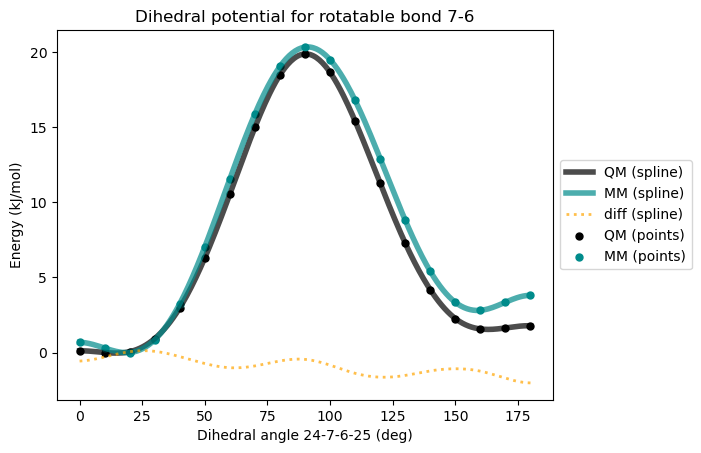

* Info * Dihedral MM parameters have been reparameterized and updated in the topology.                                    


{'dihedral_angles': array([  0.,  10.,  20.,  30.,  40.,  50.,  60.,  70.,  80.,  90., 100.,
        110., 120., 130., 140., 150., 160., 170., 180.]),
 'qm_scan_kJpermol': array([ 0.11019222,  0.        ,  0.05655326,  0.92869173,  2.9776054 ,
         6.30579376, 10.5518568 , 14.99026394, 18.48002555, 19.87419211,
        18.64784748, 15.40015694, 11.26961589,  7.28581401,  4.18273599,
         2.26197296,  1.56821093,  1.63605385,  1.78245171]),
 'mm_scan_kJpermol': array([ 0.67893207,  0.29720829,  0.        ,  0.84867934,  3.25098753,
         7.03840073, 11.56275574, 15.88308502, 19.04061522, 20.32896969,
        19.49006889, 16.78347622, 12.90931595,  8.80889678,  5.40309943,
         3.3421111 ,  2.80880201,  3.34694365,  3.80530527]),
 'maximum_difference': np.float64(2.022853563952113),
 'standard_deviation': np.float64(0.5819301498604338)}

In [16]:
ff_gen.reparameterize_dihedrals(rotatable_bond=(6,7), 
    scan_file = "24-7-6-25/24-7-6-25.xyz", 
    visualize=True, 
    initial_validation=False, 
    show_diff=True)

In [17]:
ff_gen.add_dihedral((25, 6, 7, 24), 
    barrier = 0.0, 
    phase = 0, 
    periodicity = 1)

* Info * Added dihedral 24-7-6-25                                                                                         


                                          VeloxChem Dihedral Reparameterization                                           
                                                                                                                          
* Info * Rotatable bond selected: 6-7                                                                                     
* Info * Dihedrals involved:[[5, 6, 7, 8], [5, 6, 7, 24], [8, 7, 6, 25], [24, 7, 6, 25]]                                  
                                                                                                                          
* Info * Reading QM scan from file...                                                                                     
* Info *   24-7-6-25/24-7-6-25.xyz                                                                                        
                                                                                                                          
* Info * Perform

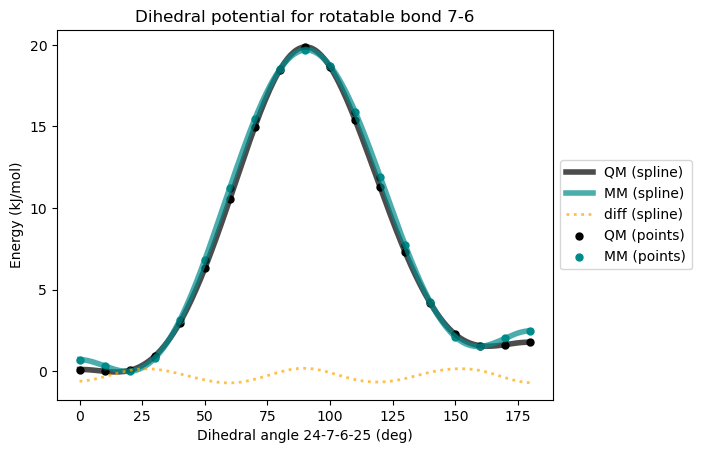

* Info * Dihedral MM parameters have been reparameterized and updated in the topology.                                    


In [18]:
results_6_7 = ff_gen.reparameterize_dihedrals(rotatable_bond=(6,7), 
    scan_file = "24-7-6-25/24-7-6-25.xyz", 
    visualize=True, 
    initial_validation=False, 
    show_diff=True)

In [19]:
# Write new gromacs files

ff_gen.write_gromacs_files("TCB_3_final", "LIG")

In [20]:
from IPython.display import Markdown, display

all_results = {
    'rotatable_bond': []
}

all_results['rotatable_bond'].append({
    'bond': (12,15),
    **results_12_15
})
all_results['rotatable_bond'].append({
    'bond': (11,10),
    **results_11_10
})
all_results['rotatable_bond'].append({
    'bond': (6,7),
    **results_6_7
})

lines = []
# header
lines.append("| Rotatable Bond | Max difference (kJ/mol) | Std deviation (kJ/mol) |")
lines.append("|----------------|-------------------------|------------------------|")

# rows
for entry in all_results['rotatable_bond']:
    bond = list(entry['bond'])
    max_diff = entry['maximum_difference']
    std    = entry['standard_deviation']
    # format to three decimal places
    lines.append(f"| {bond}      | {max_diff:.3f}                   | {std:.3f}                  |")

# join and print
markdown_table = "\n".join(lines)

display(Markdown(markdown_table))


| Rotatable Bond | Max difference (kJ/mol) | Std deviation (kJ/mol) |
|----------------|-------------------------|------------------------|
| [12, 15]      | 2.012                   | 0.714                  |
| [11, 10]      | 2.396                   | 0.997                  |
| [6, 7]      | 0.710                   | 0.305                  |

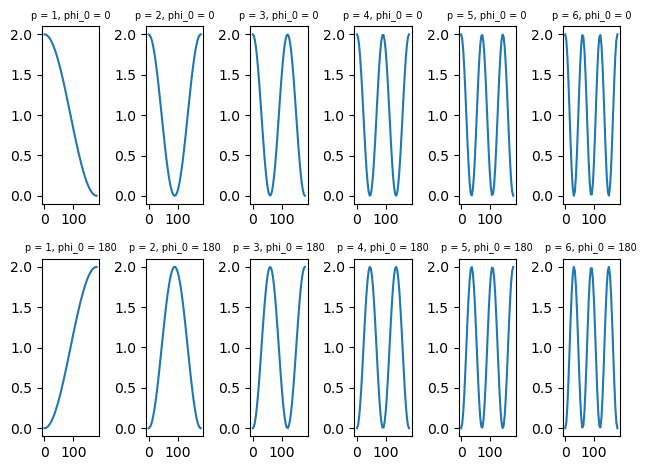

In [21]:
# Finding new dihedral potential

A = 1
# Create equation for the additional dihedral potential
def add_pot(p, phi, phi_0):
    return A*(1+math.cos(p*phi-phi_0))

# Generate angles from 0 to 180 degrees, must be in radians for cos
phi = np.radians(np.linspace(0, 180, 50))

# Plot the 12 cases from which to cherry pick from
full_list = []
# p encoded to take values between 1-6
for p in range(1, 7):
    l =[]
    # phi_0 encoded to take values 0 and 180 only, must also be in radians
    for phi_0 in [0, np.pi]:
        # Create additional potential list
        add_potential = []
        for i in range(len(phi)):
            add_potential.append(add_pot(p, phi[i], phi_0))
        l.append(add_potential)
    full_list.append(l)

# Draw graph
p = [1, 2, 3, 4, 5, 6]
phi_0 = [0, 180]

for i_p, current_p in enumerate(p):
    for i_phi_0, current_phi_0 in enumerate(phi_0):
        current_panel = len(p)*i_phi_0 + i_p + 1
        plt.subplot(2, 6, current_panel)
        plt.plot(np.degrees(phi), full_list[i_p][i_phi_0])  # plot in degrees
        plt.title(f'p = {current_p}, phi_0 = {current_phi_0}', fontsize=7)

plt.tight_layout()
plt.show()

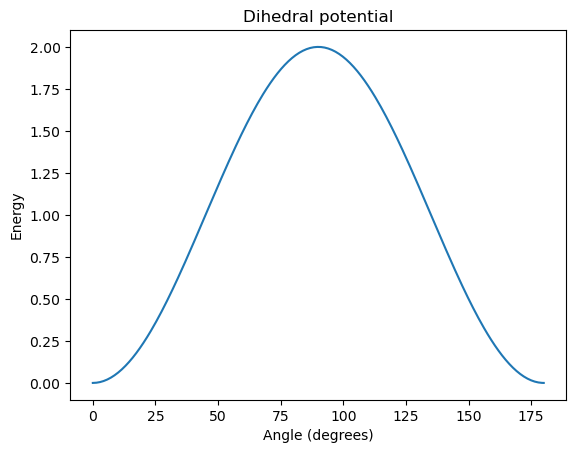

In [22]:
angles = np.linspace(0, 180, 250)        
angles_rad = np.radians(angles)          

A = 1
p = 2
phi_0 = np.radians(180)                  

add_potential = []
for i in range(len(angles_rad)):
    add_potential.append(A * (1 + math.cos(p * angles_rad[i] - phi_0)))

plt.plot(angles, add_potential)          
plt.title("Dihedral potential")
plt.xlabel("Angle (degrees)")
plt.ylabel("Energy")
plt.show()